In [5]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u


from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
dataset, variances = load_data_and_var()

In [7]:
nfws_werr = generate_nfws_from_combined_dataset_werr(dataset)

In [13]:
nfws_subset = nfws_werr[:10]
vars_subset = variances[:10]

In [14]:
L_obs = [nfw.L500.to(u.erg/u.s) for nfw in nfws_subset]

In [15]:
log_lik(p0, L_obs, vars_subset, nfws_subset)

In [20]:
log_lik(p0, L_obs, vars_subset, nfws_subset)

-0.162579385359161

In [21]:
p1 = [-30, -2]

In [22]:
log_lik(p1, L_obs, vars_subset, nfws_subset)

-0.15320039605018537

In [27]:
log_sigma0s = range(-40, -24)
initial_conditions = [[s, -2] for s in log_sigma0s]

In [28]:
log_liks = [log_lik(p, L_obs, vars_subset, nfws_subset) for p in initial_conditions]

Text(0, 0.5, 'log likelihood')

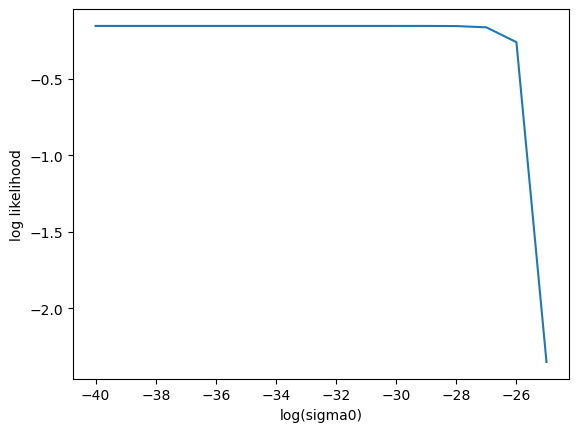

In [30]:
plt.plot(log_sigma0s, log_liks)
plt.xlabel('log(sigma0)')
plt.ylabel('log likelihood')